# 01. Exploratory Data Analysis
Goal: understand which customers churn before building a model.
Target: `Churn` (1 = customer left, 0 = stayed).

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
from src.clean import load_clean

df = load_clean()
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## Structure and data quality

In [2]:
df.info()
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

## Class balance
Accuracy alone would be misleading if the classes are imbalanced.

In [3]:
print(df["Churn"].value_counts())
df["Churn"].value_counts(normalize=True).round(3)

Churn
0    5174
1    1869
Name: count, dtype: int64


Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

## Churn rate by categorical features

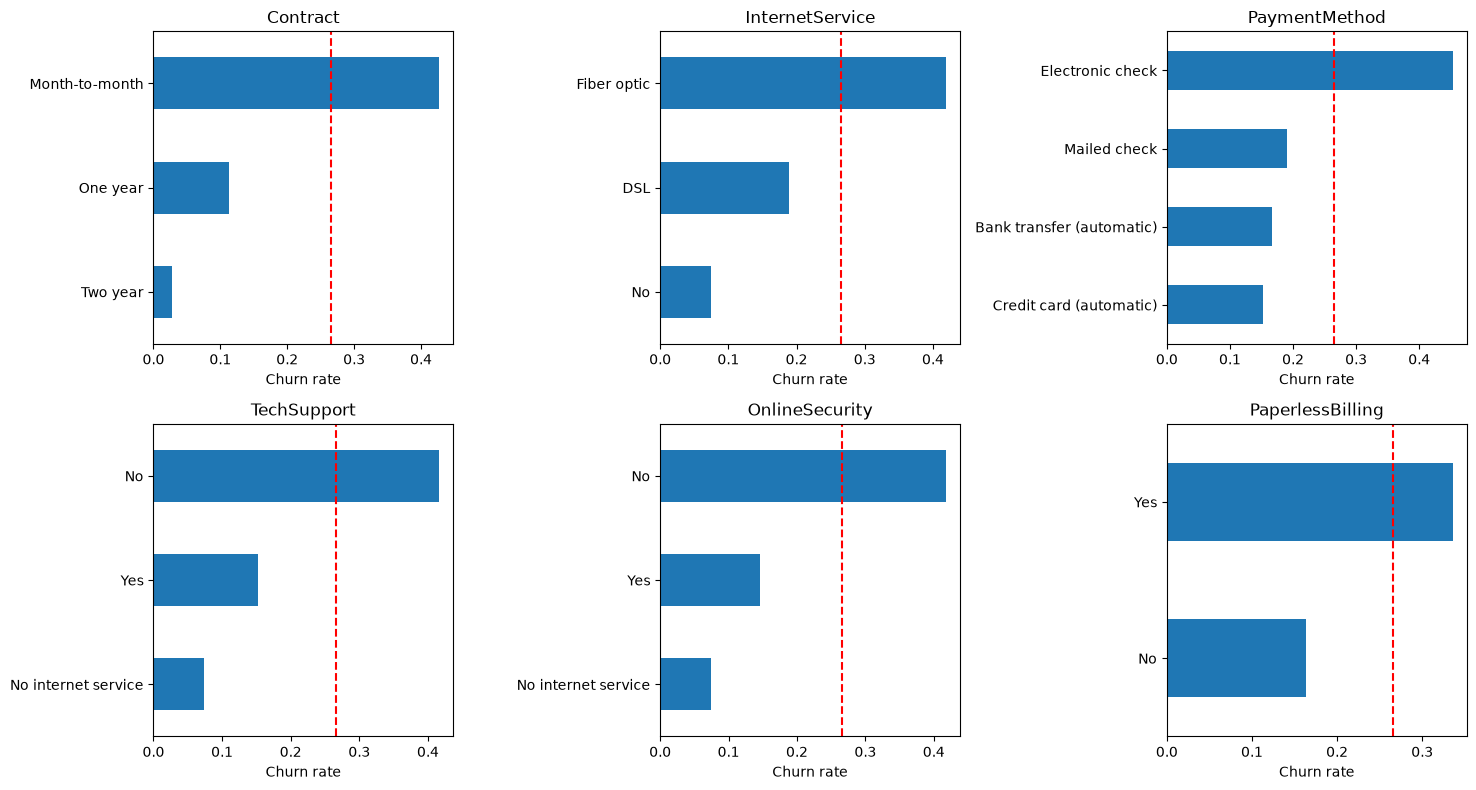

In [4]:
cats = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cats):
    df.groupby(col)["Churn"].mean().sort_values().plot.barh(ax=ax)
    ax.set(title=col, xlabel="Churn rate", ylabel="")
    ax.axvline(df["Churn"].mean(), color="red", ls="--")
plt.tight_layout()
plt.show()

## Numeric features vs churn

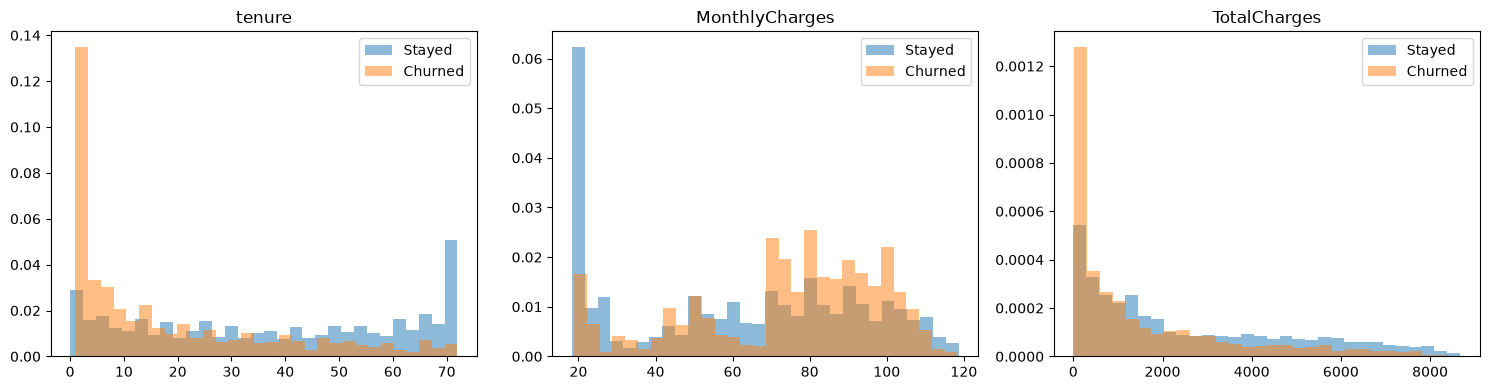

In [5]:
nums = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, nums):
    for label, g in df.groupby("Churn"):
        ax.hist(g[col], bins=30, alpha=0.5, label=["Stayed", "Churned"][label], density=True)
    ax.set(title=col)
    ax.legend()
plt.tight_layout()
plt.show()

## Findings
- The classes are imbalanced: 26.5% of customers churned, so accuracy is a poor metric. We will focus on recall, precision and F1 for the churn class.
- No missing values after cleaning. 22 duplicate rows exist, but the dataset has no customer ID, so they are probably different customers with identical plans and we keep them.
- Contract type is the strongest signal: month-to-month churn is 42.7%, one-year 11.3%, two-year 2.8%.
- Fiber optic customers churn far more (41.9%) than DSL (19.0%); customers without tech support churn at 41.6% vs 15.2% with it.
- Electronic check payers churn at 45.3%, versus 15-19% for the other payment methods.
- Churners are newer and pay more: median tenure 10 vs 38 months, median monthly charge 79.65 vs 64.43.
- Next: encode categories, scale numbers and handle the imbalance in a modelling pipeline.